In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor


In [3]:
data = fetch_openml("yacht_hydrodynamics", version=1, as_frame=True, parser="auto")
df = data.frame.copy()
df.columns = [
    "LongPos",
    "PrisCoeff",
    "LengthDisp",
    "BeamDraught",
    "LengthBeam",
    "FroudeNum",
    "Resistance"
]
df = df.astype(float)
print(f"Shape: {df.shape}")
print(df.head())

Shape: (308, 7)
   LongPos  PrisCoeff  LengthDisp  BeamDraught  LengthBeam  FroudeNum  \
0     -2.3      0.568        4.78         3.99        3.17      0.125   
1     -2.3      0.568        4.78         3.99        3.17      0.150   
2     -2.3      0.568        4.78         3.99        3.17      0.175   
3     -2.3      0.568        4.78         3.99        3.17      0.200   
4     -2.3      0.568        4.78         3.99        3.17      0.225   

   Resistance  
0        0.11  
1        0.27  
2        0.47  
3        0.78  
4        1.18  


In [4]:
print(df.describe().round(4))
print(f"\nMissing values:\n{df.isnull().sum()}")

        LongPos  PrisCoeff  LengthDisp  BeamDraught  LengthBeam  FroudeNum  \
count  308.0000   308.0000    308.0000     308.0000    308.0000   308.0000   
mean    -2.3818     0.5641      4.7886       3.9368      3.2068     0.2875   
std      1.5132     0.0233      0.2531       0.5482      0.2480     0.1009   
min     -5.0000     0.5300      4.3400       2.8100      2.7300     0.1250   
25%     -2.4000     0.5460      4.7700       3.7500      3.1500     0.2000   
50%     -2.3000     0.5650      4.7800       3.9550      3.1500     0.2875   
75%     -2.3000     0.5740      5.1000       4.1700      3.5100     0.3750   
max      0.0000     0.6000      5.1400       5.3500      3.6400     0.4500   

       Resistance  
count    308.0000  
mean      10.4954  
std       15.1605  
min        0.0100  
25%        0.7775  
50%        3.0650  
75%       12.8150  
max       62.4200  

Missing values:
LongPos        0
PrisCoeff      0
LengthDisp     0
BeamDraught    0
LengthBeam     0
FroudeNum      

In [5]:
features = [c for c in df.columns if c != "Resistance"]
target = "Resistance"

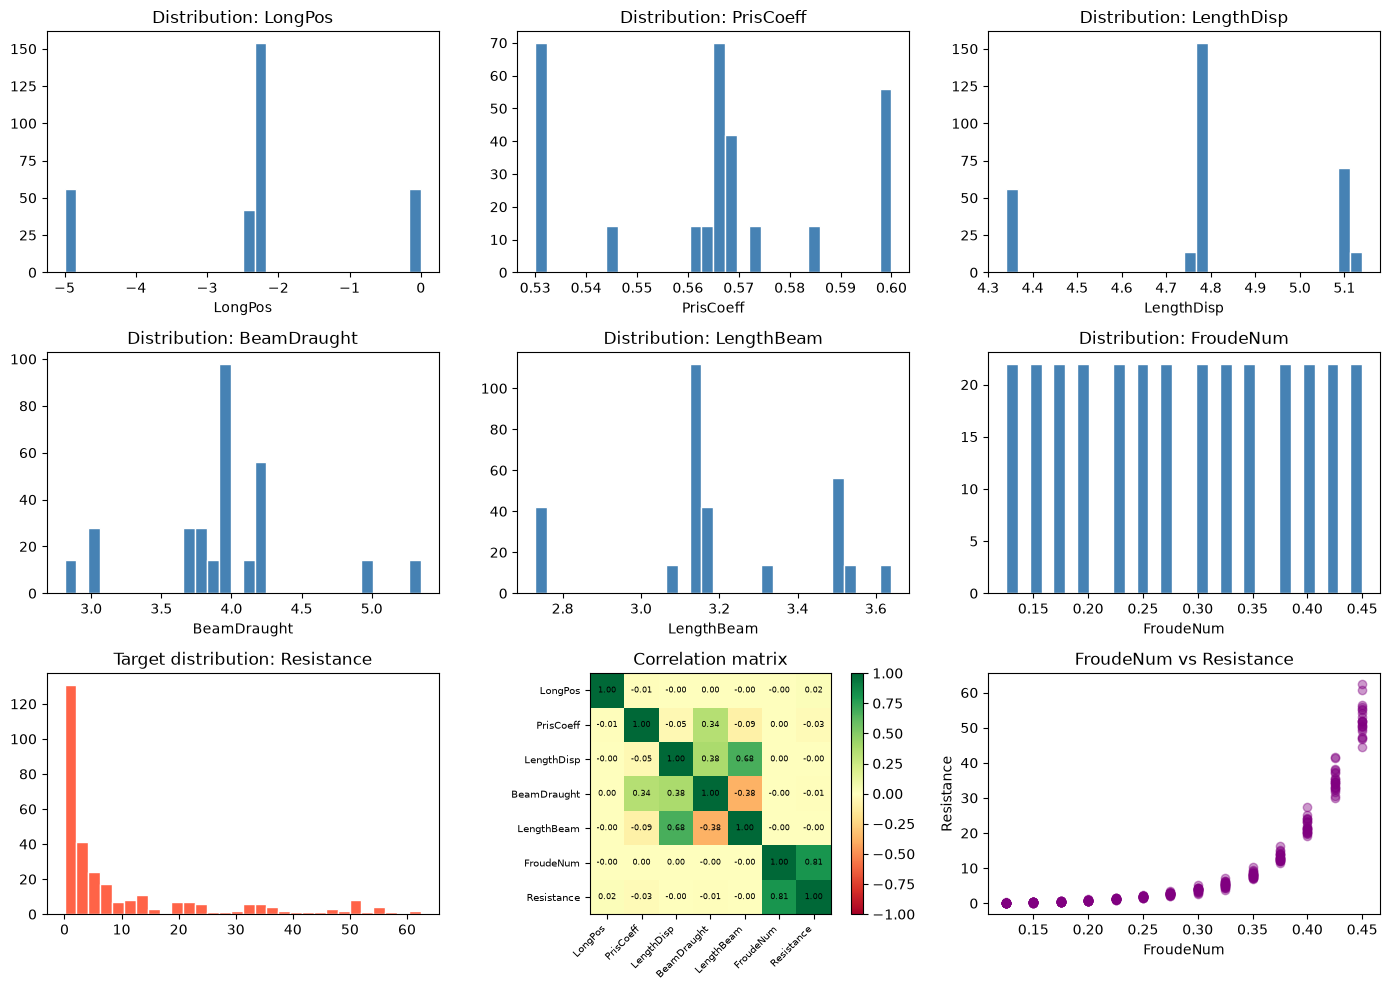

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.ravel()

for i, col in enumerate(features):
    axes[i].hist(df[col], bins=30, color="steelblue", edgecolor="white")
    axes[i].set_title(f"Distribution: {col}")
    axes[i].set_xlabel(col)

axes[6].hist(df[target], bins=30, color="tomato", edgecolor="white")
axes[6].set_title(f"Target distribution: {target}")

corr = df.corr()
im = axes[7].imshow(corr.values, cmap="RdYlGn", vmin=-1, vmax=1)
axes[7].set_xticks(range(len(df.columns)))
axes[7].set_yticks(range(len(df.columns)))
axes[7].set_xticklabels(df.columns, rotation=45, ha="right", fontsize=7)
axes[7].set_yticklabels(df.columns, fontsize=7)
for r in range(len(df.columns)):
    for c in range(len(df.columns)):
        axes[7].text(c, r, f"{corr.values[r, c]:.2f}", ha="center", va="center", fontsize=6)
axes[7].set_title("Correlation matrix")
fig.colorbar(im, ax=axes[7])

axes[8].scatter(df["FroudeNum"], df["Resistance"], alpha=0.4, color="purple")
axes[8].set_xlabel("FroudeNum")
axes[8].set_ylabel("Resistance")
axes[8].set_title("FroudeNum vs Resistance")

plt.tight_layout()
plt.show()

In [8]:
X = df[features].values
y = df[target].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)


Train: (246, 6), Test: (62, 6)


In [9]:
models = {
    "LinearRegression": Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]),
    "Ridge": Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]),
    "Lasso": Pipeline([("sc", StandardScaler()), ("m", Lasso(alpha=0.1))]),
    "ElasticNet": Pipeline([("sc", StandardScaler()), ("m", ElasticNet(alpha=0.1, l1_ratio=0.5))]),
    "KNN": Pipeline([("sc", StandardScaler()), ("m", KNeighborsRegressor(n_neighbors=5))]),
    "DecisionTree": DecisionTreeRegressor(random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=200, random_state=42),
    "SVR": Pipeline([("sc", StandardScaler()), ("m", SVR(kernel="rbf", C=100, epsilon=0.1))]),
}


In [10]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
all_results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    cv_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2").mean()

    all_results[name] = {
        "model": model,
        "y_pred": y_pred,
        "rmse": rmse,
        "mae": mae,
        "r2": r2,
        "cv_r2": cv_r2,
    }
    print(f"{name:<20} RMSE {rmse:7.4f}  MAE {mae:7.4f}  R2 {r2:.4f}  CV-R2 {cv_r2:.4f}")

LinearRegression     RMSE  8.2221  MAE  6.8075  R2 0.5450  CV-R2 0.6090
Ridge                RMSE  8.2071  MAE  6.7847  R2 0.5467  CV-R2 0.6111
Lasso                RMSE  8.1838  MAE  6.7886  R2 0.5493  CV-R2 0.6158
ElasticNet           RMSE  8.0496  MAE  6.5303  R2 0.5639  CV-R2 0.6170
KNN                  RMSE  8.7679  MAE  3.8437  R2 0.4826  CV-R2 0.5566
DecisionTree         RMSE  0.5392  MAE  0.3277  R2 0.9980  CV-R2 0.9921
RandomForest         RMSE  0.5440  MAE  0.3060  R2 0.9980  CV-R2 0.9941
GradientBoosting     RMSE  0.6025  MAE  0.2623  R2 0.9976  CV-R2 0.9980
SVR                  RMSE  2.9625  MAE  1.5491  R2 0.9409  CV-R2 0.9226


In [16]:
rows = [{"model": n, "RMSE": r["rmse"], "MAE": r["mae"],
         "R2": r["r2"], "CV_R2": r["cv_r2"]}
        for n, r in all_results.items()]
results_df = pd.DataFrame(rows).set_index("model").sort_values("R2", ascending=False)
print("\n=== Results (test set) ===")
print(results_df.round(4))


=== Results (test set) ===
                    RMSE     MAE      R2   CV_R2
model                                           
DecisionTree      0.5392  0.3277  0.9980  0.9921
RandomForest      0.5440  0.3060  0.9980  0.9941
GradientBoosting  0.6025  0.2623  0.9976  0.9980
SVR               2.9625  1.5491  0.9409  0.9226
ElasticNet        8.0496  6.5303  0.5639  0.6170
Lasso             8.1838  6.7886  0.5493  0.6158
Ridge             8.2071  6.7847  0.5467  0.6111
LinearRegression  8.2221  6.8075  0.5450  0.6090
KNN               8.7679  3.8437  0.4826  0.5566


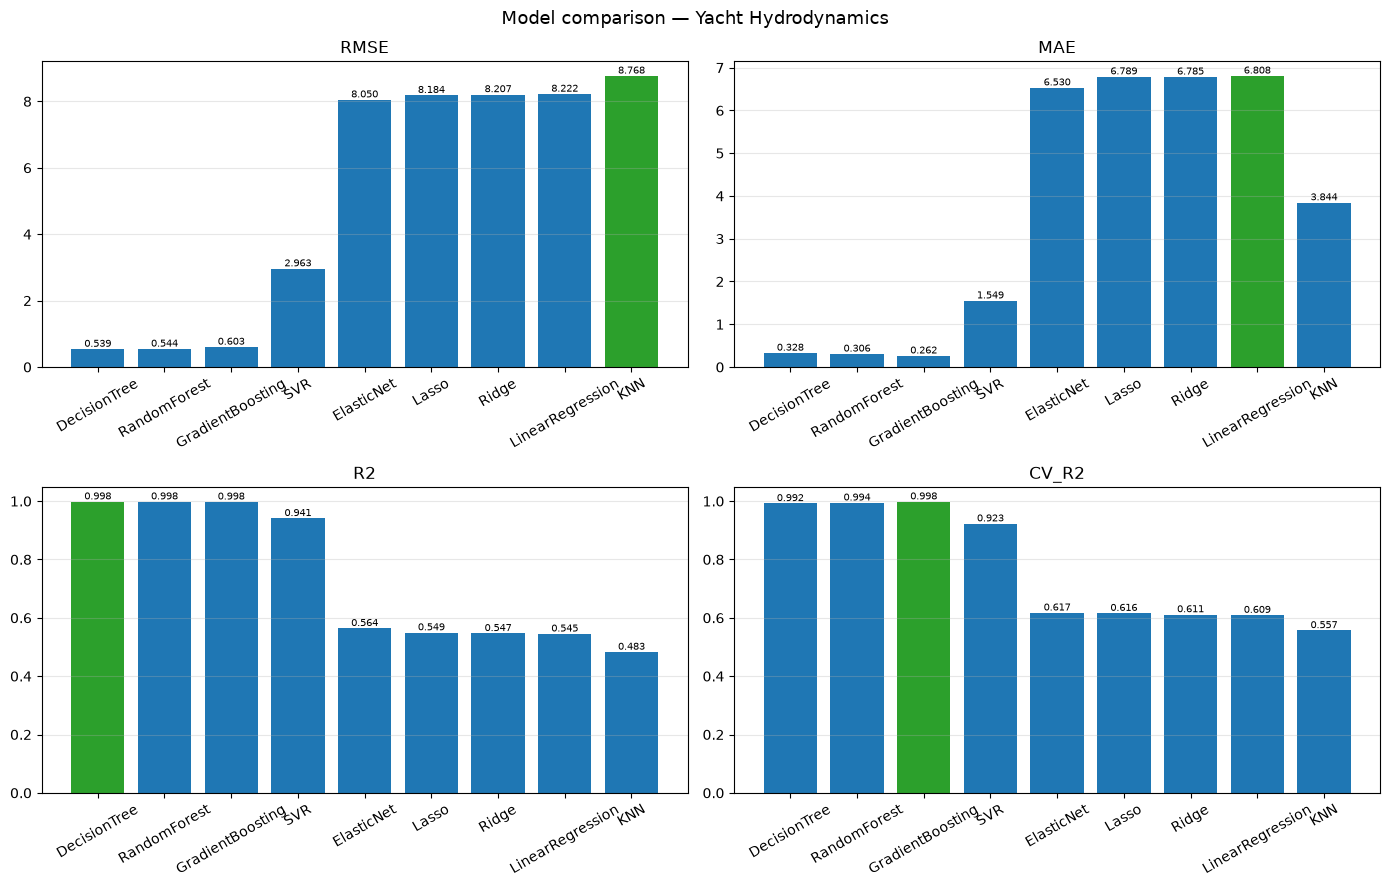

In [12]:
metrics = ["RMSE", "MAE", "R2", "CV_R2"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, m in zip(axes.ravel(), metrics):
    bars = ax.bar(results_df.index, results_df[m],
                  color=["tab:green" if v == results_df[m].max()
                         else "tab:blue" for v in results_df[m]])
    ax.set_title(m)
    ax.tick_params(axis="x", rotation=30)
    ax.bar_label(bars, fmt="%.3f", fontsize=7)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Model comparison — Yacht Hydrodynamics", fontsize=13)
plt.tight_layout()
plt.show()

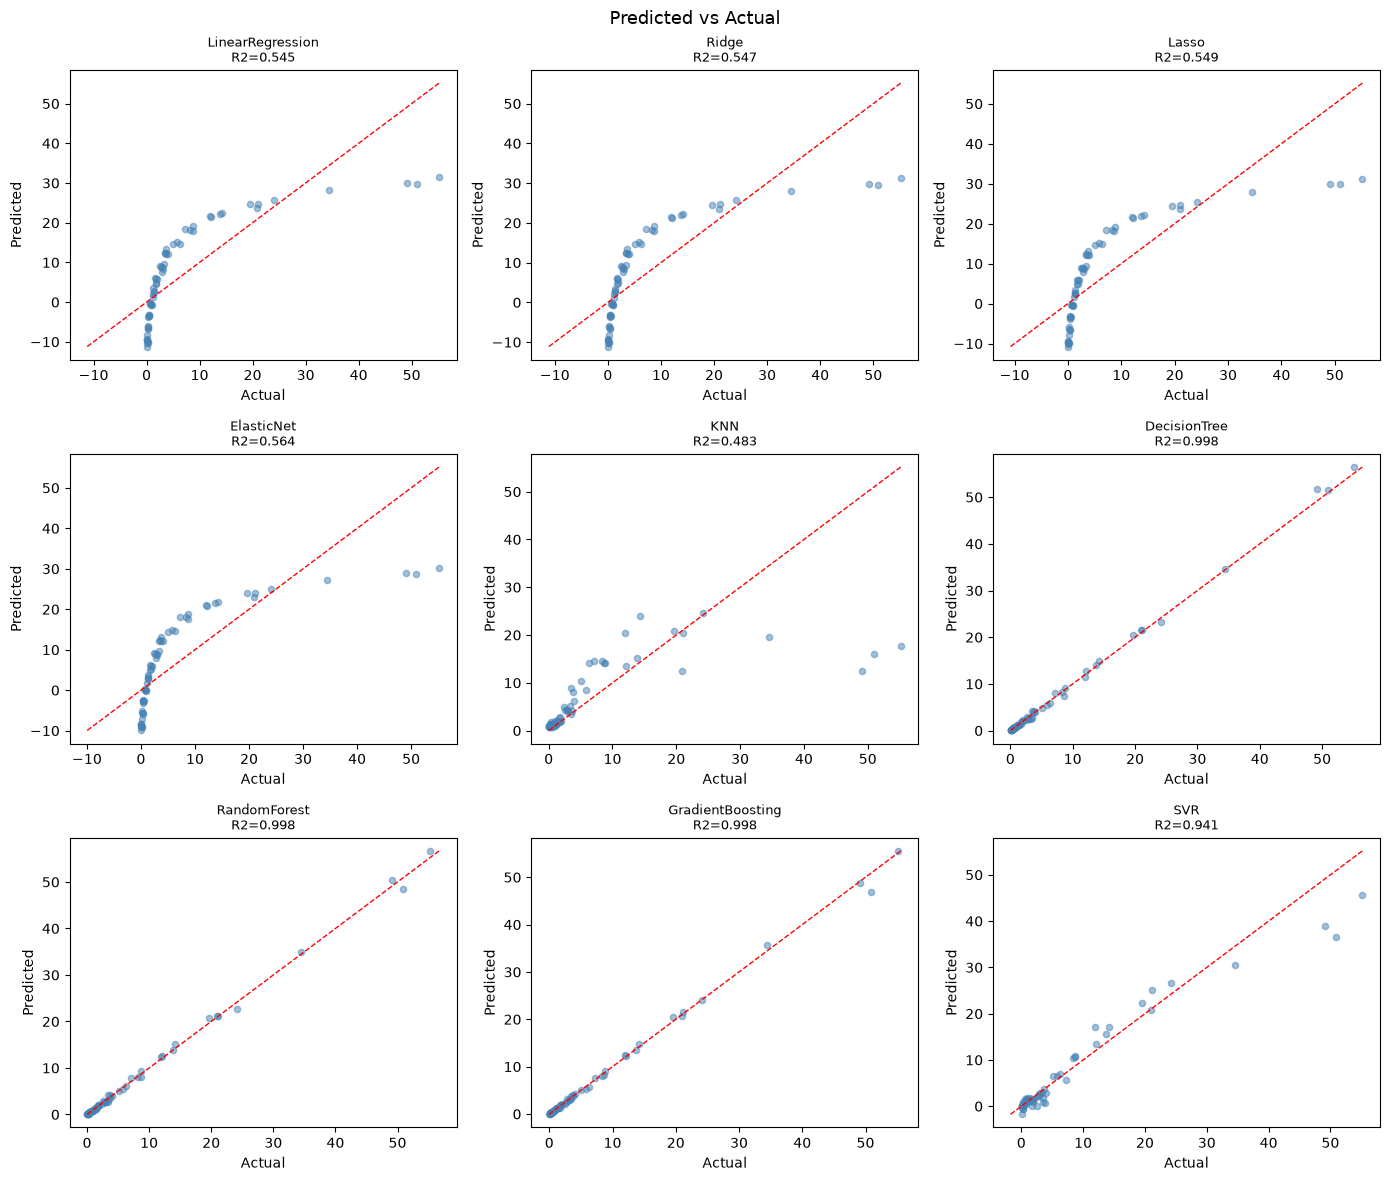

In [14]:
n = len(all_results)
cols = 3
rows_n = -(-n // cols)
fig, axes = plt.subplots(rows_n, cols, figsize=(14, rows_n * 4))
axes = axes.ravel()
for ax, (name, r) in zip(axes, all_results.items()):
    ax.scatter(y_test, r["y_pred"], alpha=0.5, s=20, color="steelblue")
    lims = [min(y_test.min(), r["y_pred"].min()), max(y_test.max(), r["y_pred"].max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_title(f"{name}\nR2={r['r2']:.3f}", fontsize=9)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
for ax in axes[len(all_results):]:
    ax.set_visible(False)
fig.suptitle("Predicted vs Actual", fontsize=13)
plt.tight_layout()
plt.show()

In [17]:
feature_names = features

In [18]:
import joblib

best = all_results["GradientBoosting"]["model"]
joblib.dump({
    "model": best,
    "scaler": scaler,
    "feature_names": feature_names,
}, "yacht_gbr.pkl")
print("Saved yacht_gbr.pkl")

Saved yacht_gbr.pkl
